In [1]:
from pathlib import Path
import sys
project_root = Path.cwd()
while not (project_root / 'src').is_dir() and project_root != project_root.parent:
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.model import SpectralNMF
import numpy as np
from matplotlib import pyplot as plt


In [2]:
project_root = Path.cwd()
while not (project_root / 'src').is_dir() and project_root != project_root.parent:
    project_root = project_root.parent


In [3]:
# Load the existing 3800-4200 A stellar basis from the project cache.
F_path = project_root / 'cache/stellar/nmf_F_full_15543661.npy'


In [4]:
stellar = SpectralNMF.load(F_path)
wave = stellar.wavelengths
print('Loaded stellar basis:', stellar.cache_path)
print('Basis shape:', stellar.components_.shape)


Loaded stellar basis: /home/mward19/Documents/stellar-continuum-normalization/cache/stellar/nmf_F_full_15543661.npy
Basis shape: (16, 34530)


In [5]:
F = stellar.components_


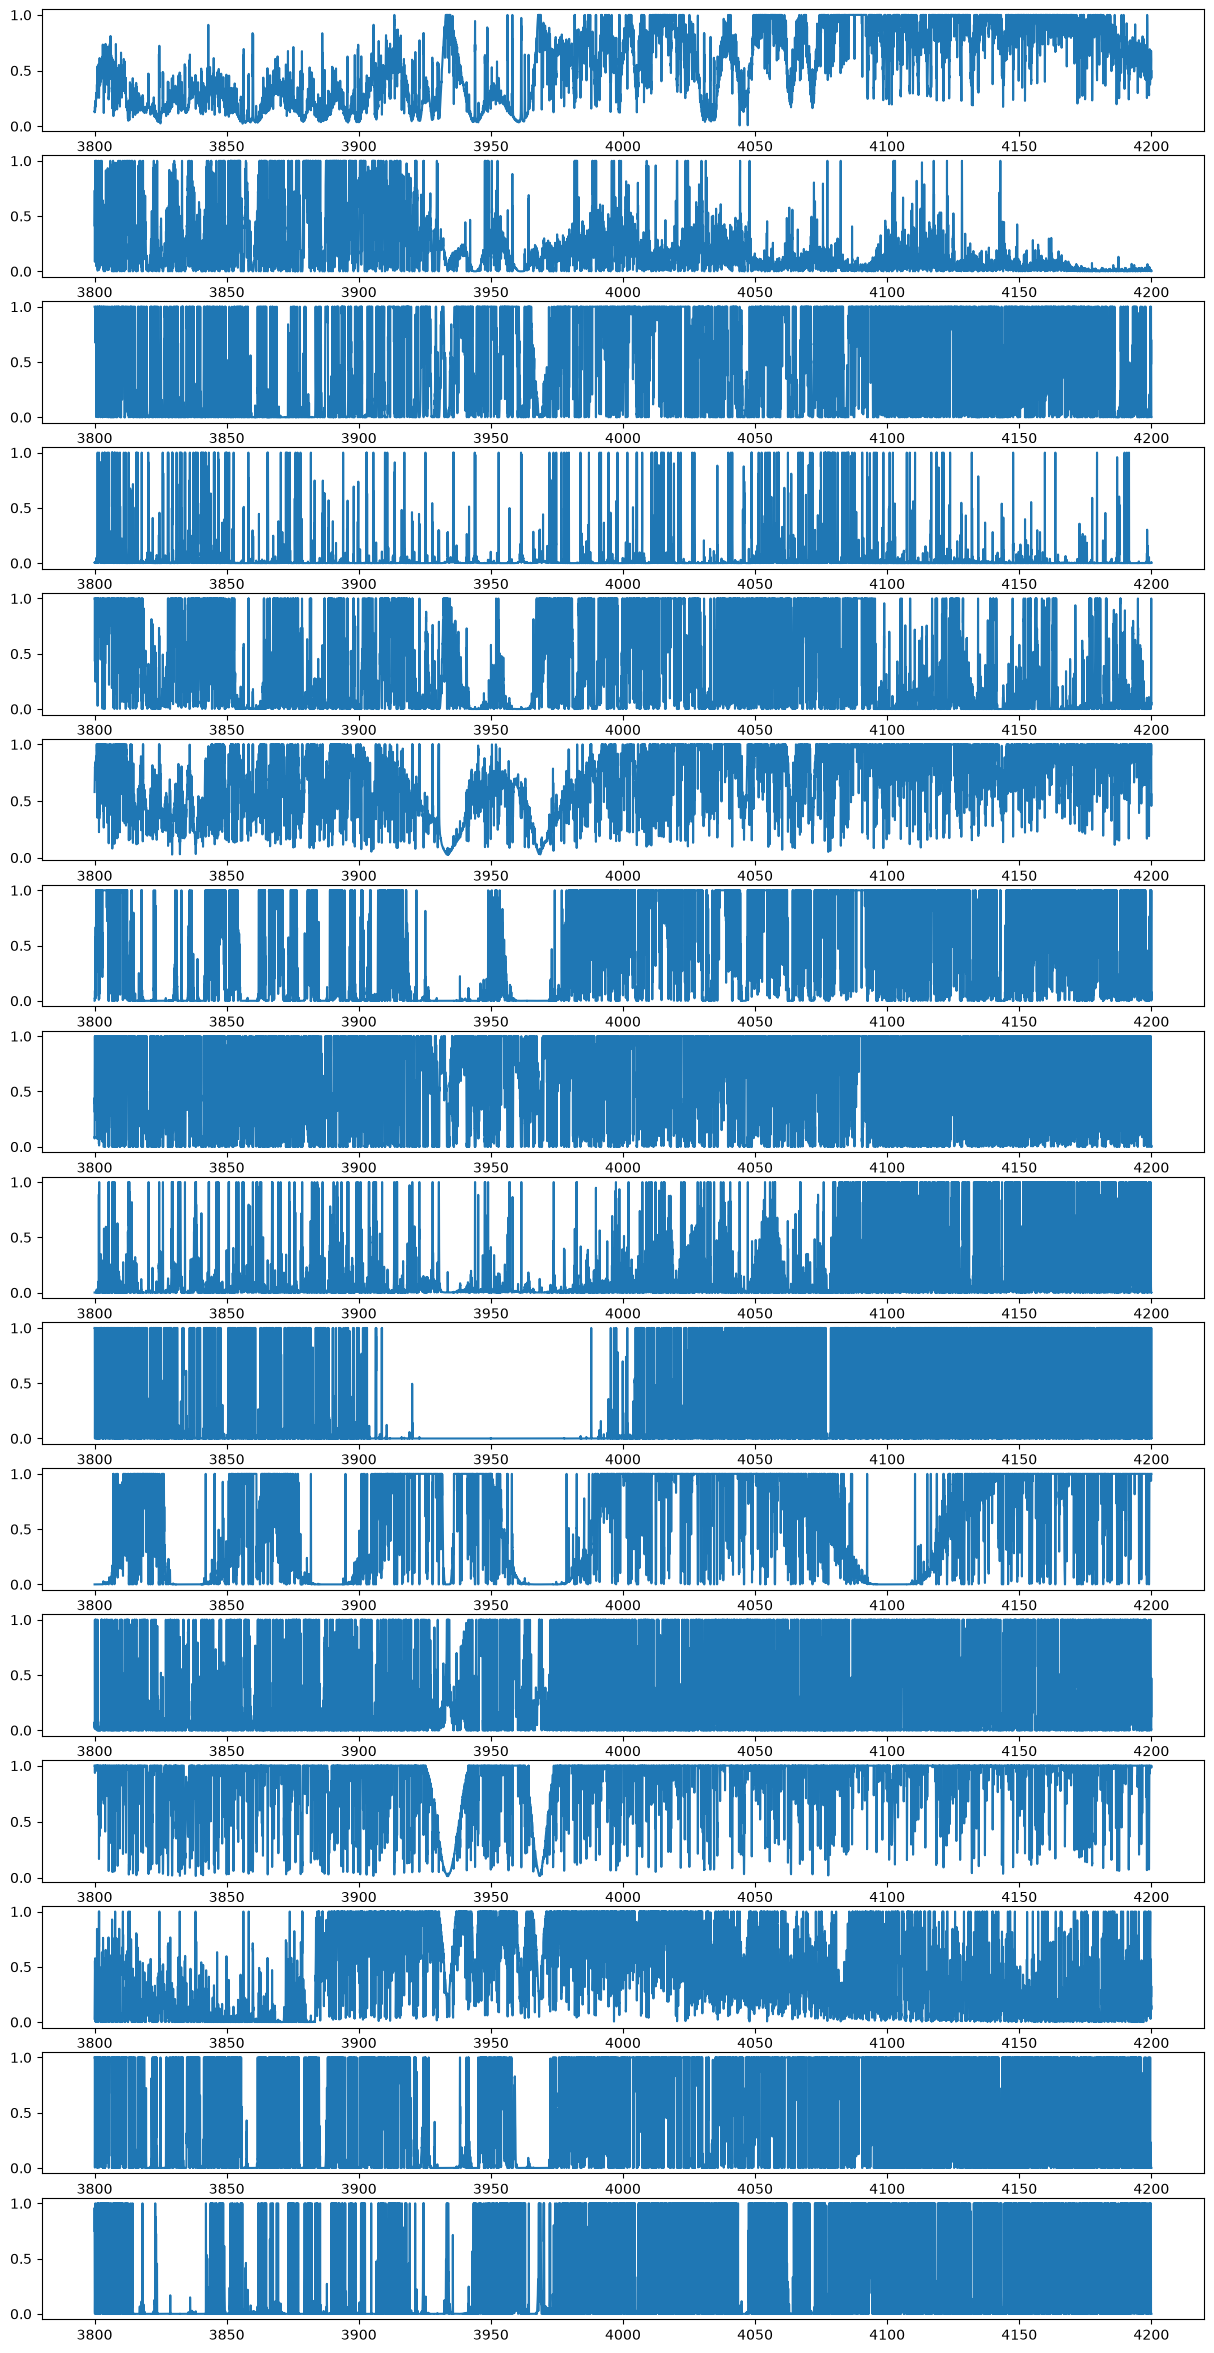

In [6]:
_n_vecs = 16
_fig, _axes = plt.subplots(_n_vecs, figsize=(15, 30))

for _i, _ax in enumerate(_axes):
    _ax.plot(wave, np.exp(-F[_i]))

plt.show()


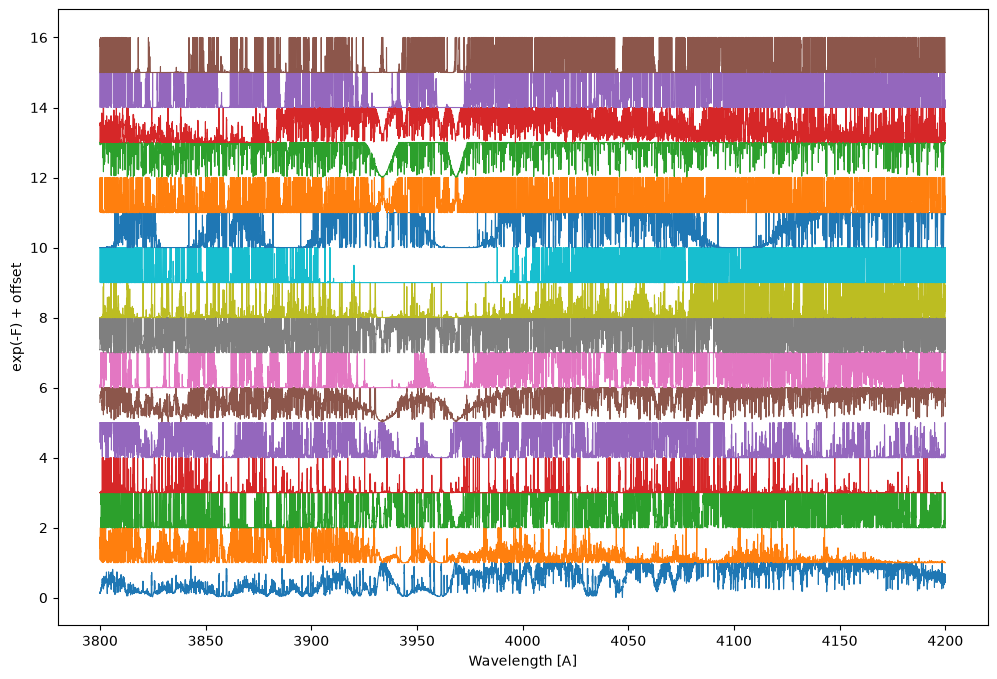

In [7]:
# Like Figure 1 of Casey et al. (2026): basis vectors exp(-F) with offsets, 3800-4200 A
_window = (wave >= 3800) & (wave <= 4200)
_fig, _ax = plt.subplots(figsize=(12, 8))
for _i, _f in enumerate(F):
    _ax.plot(wave[_window], np.exp(-_f[_window]) + _i, lw=0.8)
_ax.set_xlabel("Wavelength [A]")
_ax.set_ylabel("exp(-F) + offset")
plt.show()
